# 01 · EDA y preprocesamiento — Detección de fraude (PaySim)

**Objetivo:** entender el dataset, verificar las hipótesis de fraude del enunciado, construir los features y
generar los splits temporales que usarán los notebooks siguientes.

**Reglas que aplica este notebook**
- `step <= 400` = referencia/entrenamiento; `step >= 401` = producción (solo monitoreo, nunca entrenamiento).
- Los nombres de cuenta (`nameOrig`, `nameDest`) se descartan en la ingesta; solo sobrevive el patrón `is_merchant_dest`.
- Todos los features son fila a fila (sin `fit`), por lo que no pueden filtrar información entre splits.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

from fraud_detection import config
from fraud_detection.data import (
    build_transactions_parquet,
    load_transactions,
    summarize_account_names,
)
from fraud_detection.features import DERIVED_FEATURES, MODEL_FEATURES, add_features
from fraud_detection.plots import COLOR_FRAUD, COLOR_LEGIT, COLOR_NEUTRAL, finish, set_style
from fraud_detection.split import filter_model_scope, split_reference_production, split_train_test

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 50)
np.random.seed(config.SEED)

## 1. Ingesta: CSV → Parquet

El CSV pesa ~470 MB y tiene 6.36 M de filas. Se lee con **polars en modo lazy/streaming** y un schema explícito
(`step` int16, `type` Enum, montos float64, flags int8):

- **float64 en montos** porque llegan a ~9·10⁷ y float32 (~7 cifras significativas) perdería los centavos, que es justo
  la señal de los features de consistencia de saldos.
- Los nombres de cuenta se perfilan (solo agregados) y luego se **descartan**: son identificadores, no features, y son
  la parte más pesada en RAM.

Si el Parquet ya existe no se reconstruye (`overwrite=False`).

In [2]:
parquet_path = build_transactions_parquet()
print(parquet_path.relative_to(config.PROJECT_ROOT), f"{parquet_path.stat().st_size / 1e6:,.0f} MB")
summarize_account_names()

data/processed/transactions.parquet 113 MB


,value
rows,6362620
unique_orig,6353307
unique_dest,2722362
orig_prefix_C,6362620
orig_prefix_M,0
dest_prefix_C,4211125
dest_prefix_M,2151495


**Lectura de los identificadores**
- `nameOrig` es prácticamente único por transacción (~6.35 M de valores en 6.36 M de filas): no hay historial por
  cliente origen que explotar, así que no se pierde nada al descartarlo.
- Todos los orígenes son clientes (`C…`). Los destinos `M…` (merchants) son exactamente las 2,151,495 transacciones
  `PAYMENT` (se confirma abajo).

## 2. Calidad de datos

In [3]:
df = load_transactions()
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | RAM: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print(f"Nulos totales: {int(df.isna().sum().sum())}")
print(f"Steps: {df['step'].min()} – {df['step'].max()} ({df['step'].nunique()} distintos)")
df.dtypes.to_frame("dtype").T

Filas: 6,362,620 | Columnas: 10 | RAM: 293 MB
Nulos totales: 0
Steps: 1 – 743 (743 distintos)


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,is_merchant_dest
dtype,int16,category,float64,float64,float64,float64,float64,int8,int8,int8


In [4]:
df.describe(percentiles=[0.5, 0.99]).T

,count,mean,std,min,50%,99%,max
step,"6,362,620.0000",243.3972,142.3320,1.0000,239.0000,681.0000,743.0000
amount,"6,362,620.0000","179,861.9035","603,858.2315",0.0000,"74,871.9400","1,615,979.4716","92,445,516.6400"
oldbalanceOrg,"6,362,620.0000","833,883.1041","2,888,242.6730",0.0000,"14,208.0000","16,027,256.1337","59,585,040.3700"
newbalanceOrig,"6,362,620.0000","855,113.6686","2,924,048.5030",0.0000,0.0000,"16,176,160.5580","49,585,040.3700"
oldbalanceDest,"6,362,620.0000","1,100,701.6665","3,399,180.1130",0.0000,"132,705.6650","12,371,819.1548","356,015,889.3500"
newbalanceDest,"6,362,620.0000","1,224,996.3982","3,674,128.9421",0.0000,"214,661.4400","13,137,866.9410","356,179,278.9200"
isFraud,"6,362,620.0000",0.0013,0.0359,0.0000,0.0000,0.0000,1.0000
isFlaggedFraud,"6,362,620.0000",0.0000,0.0016,0.0000,0.0000,0.0000,1.0000
is_merchant_dest,"6,362,620.0000",0.3381,0.4731,0.0000,0.0000,1.0000,1.0000


Sin nulos. Los saldos tienen muchos ceros (se analizan en la sección 5). El monto máximo es 9.2·10⁷.

## 3. Target: desbalance y tipo de transacción

In [5]:
by_type = (
    df.groupby("type", observed=True)
    .agg(transacciones=("isFraud", "size"), fraudes=("isFraud", "sum"), tasa_fraude=("isFraud", "mean"),
         dest_merchant=("is_merchant_dest", "mean"))
    .sort_values("transacciones", ascending=False)
)
total_rate = df["isFraud"].mean()
print(f"Tasa global de fraude: {total_rate:.4%} ({df['isFraud'].sum():,} fraudes)")
by_type

Tasa global de fraude: 0.1291% (8,213 fraudes)


,transacciones,fraudes,tasa_fraude,dest_merchant
type,,,,
CASH_OUT,2237500,4116,0.0018,0.0000
PAYMENT,2151495,0,0.0000,1.0000
CASH_IN,1399284,0,0.0000,0.0000
TRANSFER,532909,4097,0.0077,0.0000
DEBIT,41432,0,0.0000,0.0000


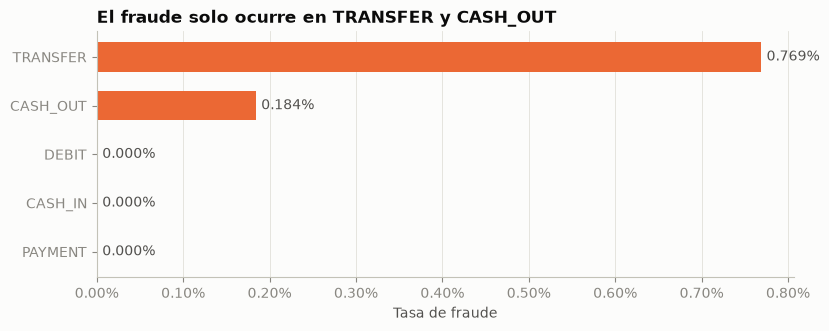

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2))
plot_df = by_type.sort_values("tasa_fraude")
bars = ax.barh(plot_df.index.astype(str), plot_df["tasa_fraude"], color=COLOR_FRAUD, height=0.6)
ax.bar_label(bars, labels=[f"{v:.3%}" for v in plot_df["tasa_fraude"]], padding=4, color="#52514e")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
finish(ax, "El fraude solo ocurre en TRANSFER y CASH_OUT", "Tasa de fraude", "")
plt.show()

**Conclusiones**
- Tasa de fraude global **0.129 %** (8,213 de 6.36 M) → desbalance extremo (~1:774). Accuracy no sirve: un modelo que
  siempre dice "no fraude" tendría 99.87 %. Se usarán PR-AUC, recall, precision, F1/F2.
- **El fraude ocurre solo en `TRANSFER` (0.77 %) y `CASH_OUT` (0.18 %)**, ~4.1 K casos en cada uno, coherente con el
  modus operandi descrito (tomar la cuenta → transferir → retirar).
- Los destinos merchant aparecen **solo** en `PAYMENT`, donde no hay fraude. El patrón sugerido "transferencias grandes a
  merchants" **no existe en estos datos**.

**Decisión de alcance del modelo:** se entrena y se puntúa solo `TRANSFER` + `CASH_OUT` (2.77 M filas, −56 % de RAM).
Los demás tipos reciben score 0 por regla de negocio. En monitoreo se vigilará si aparece fraude fuera de este alcance.
Consecuencia: dentro del alcance, `is_merchant_dest` es constante (0) y se excluye del modelo.

## 4. Dimensión temporal

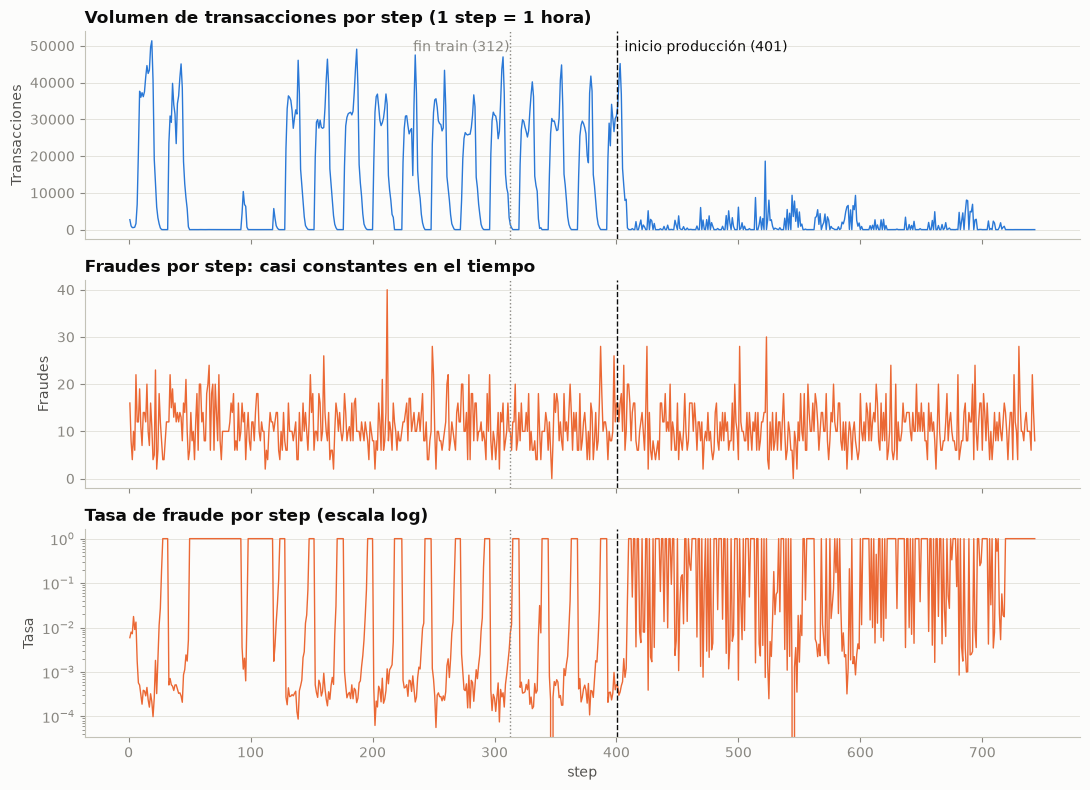

In [7]:
per_step = df.groupby("step").agg(transacciones=("isFraud", "size"), fraudes=("isFraud", "sum"))
per_step["tasa_fraude"] = per_step["fraudes"] / per_step["transacciones"]

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(per_step.index, per_step["transacciones"], color=COLOR_LEGIT, linewidth=1)
finish(axes[0], "Volumen de transacciones por step (1 step = 1 hora)", "", "Transacciones")
axes[1].plot(per_step.index, per_step["fraudes"], color=COLOR_FRAUD, linewidth=1)
finish(axes[1], "Fraudes por step: casi constantes en el tiempo", "", "Fraudes")
axes[2].plot(per_step.index, per_step["tasa_fraude"], color=COLOR_FRAUD, linewidth=1)
axes[2].set_yscale("log")
finish(axes[2], "Tasa de fraude por step (escala log)", "step", "Tasa")
for ax in axes:
    ax.axvline(config.TRAIN_MAX_STEP + 0.5, color=COLOR_NEUTRAL, linestyle=":", linewidth=1)
    ax.axvline(config.REFERENCE_MAX_STEP + 0.5, color="#0b0b0b", linestyle="--", linewidth=1)
axes[0].annotate("fin train (312)", (config.TRAIN_MAX_STEP, axes[0].get_ylim()[1] * 0.9), ha="right", color=COLOR_NEUTRAL)
axes[0].annotate("  inicio producción (401)", (config.REFERENCE_MAX_STEP, axes[0].get_ylim()[1] * 0.9), color="#0b0b0b")
plt.tight_layout()
plt.show()

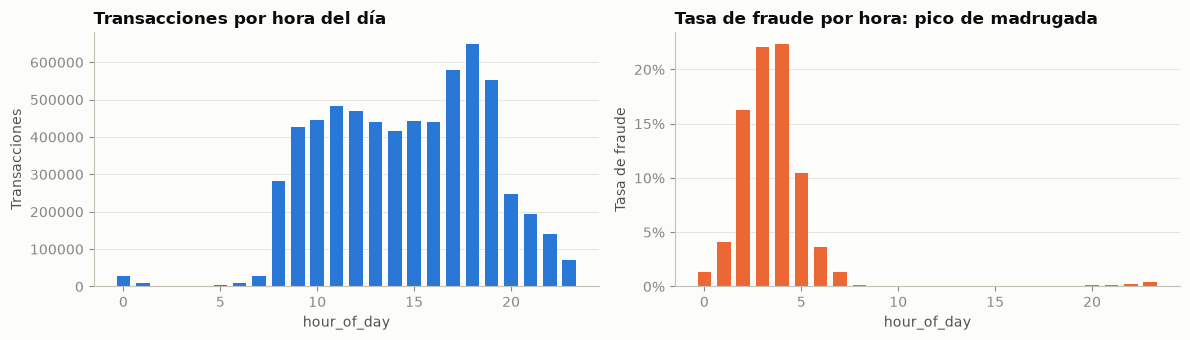

hour_of_day,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
transacciones,"27,111.0000","9,018.0000","2,007.0000","1,241.0000","1,641.0000","3,420.0000","8,988.0000","26,915.0000","283,518.0000","425,729.0000","445,992.0000","483,418.0000","468,474.0000","439,653.0000","416,686.0000","441,612.0000","439,941.0000","580,509.0000","647,814.0000","553,728.0000","247,806.0000","194,555.0000","141,257.0000","71,587.0000"
fraudes,358.0000,372.0000,326.0000,274.0000,366.0000,358.0000,328.0000,368.0000,341.0000,375.0000,324.0000,339.0000,346.0000,353.0000,341.0000,345.0000,353.0000,343.0000,342.0000,340.0000,347.0000,351.0000,323.0000,300.0000
tasa_fraude,0.0132,0.0413,0.1624,0.2208,0.2230,0.1047,0.0365,0.0137,0.0012,0.0009,0.0007,0.0007,0.0007,0.0008,0.0008,0.0008,0.0008,0.0006,0.0005,0.0006,0.0014,0.0018,0.0023,0.0042


In [8]:
df["hour_of_day"] = ((df["step"] - 1) % 24).astype("int8")
per_hour = df.groupby("hour_of_day").agg(transacciones=("isFraud", "size"), fraudes=("isFraud", "sum"))
per_hour["tasa_fraude"] = per_hour["fraudes"] / per_hour["transacciones"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(per_hour.index, per_hour["transacciones"], color=COLOR_LEGIT, width=0.7)
finish(axes[0], "Transacciones por hora del día", "hour_of_day", "Transacciones")
axes[1].bar(per_hour.index, per_hour["tasa_fraude"], color=COLOR_FRAUD, width=0.7)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
finish(axes[1], "Tasa de fraude por hora: pico de madrugada", "hour_of_day", "Tasa de fraude")
plt.tight_layout()
plt.show()
per_hour.T

**Conclusiones**
- El volumen legítimo es **cíclico** (día/noche) y cae fuertemente después de ~step 400; los fraudes se mantienen
  ~constantes (~11 por hora). Por eso la tasa de fraude se dispara de madrugada (hasta ~22 % a las 3–4 h) y en el
  periodo de producción.
- `hour_of_day = (step − 1) % 24` es un feature legítimo (se conoce al momento de la transacción) y generaliza a días
  nuevos. **`step` crudo no se usa**: no es estacionario y el modelo extrapolaría fuera del rango visto.
- **Alerta para monitoreo:** en producción (`step >= 401`) la tasa de fraude será varias veces la de entrenamiento
  (prior shift). Afecta directamente precision/PR-AUC online aunque el modelo no se degrade: se analizará en la Fase 4.

## 5. Montos, saldos y patrones de fraude (alcance TRANSFER + CASH_OUT)

Alcance del modelo: 2,770,409 filas, 8,213 fraudes (0.296%)


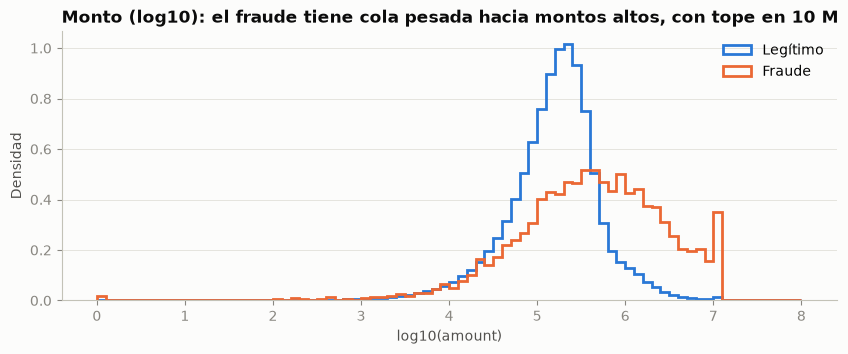

Fraudes con monto exacto 10,000,000 (tope de la simulación): 287


In [9]:
scope_raw = filter_model_scope(df)
print(f"Alcance del modelo: {len(scope_raw):,} filas, {scope_raw['isFraud'].sum():,} fraudes "
      f"({scope_raw['isFraud'].mean():.3%})")

fig, ax = plt.subplots(figsize=(10, 3.5))
bins = np.linspace(0, 8, 81)
for label, color, name in [(0, COLOR_LEGIT, "Legítimo"), (1, COLOR_FRAUD, "Fraude")]:
    values = np.log10(scope_raw.loc[scope_raw["isFraud"] == label, "amount"].clip(lower=1))
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=color, label=name)
ax.legend()
finish(ax, "Monto (log10): el fraude tiene cola pesada hacia montos altos, con tope en 10 M", "log10(amount)", "Densidad")
plt.show()

print(f"Fraudes con monto exacto 10,000,000 (tope de la simulación): "
      f"{(scope_raw.loc[scope_raw['isFraud'] == 1, 'amount'] == 10_000_000).sum():,}")

In [10]:
tol = 0.01
patterns = pd.DataFrame({
    "isFraud": scope_raw["isFraud"],
    "saldo_origen_inicial_0": scope_raw["oldbalanceOrg"] == 0,
    "saldo_origen_final_0": scope_raw["newbalanceOrig"] == 0,
    "vaciado_total (amount≈oldbalanceOrg)": (scope_raw["oldbalanceOrg"] > 0)
        & ((scope_raw["amount"] - scope_raw["oldbalanceOrg"]).abs() <= tol),
    "origen_no_cuadra": (scope_raw["newbalanceOrig"] + scope_raw["amount"] - scope_raw["oldbalanceOrg"]).abs() > tol,
    "destino_no_cuadra": (scope_raw["oldbalanceDest"] + scope_raw["amount"] - scope_raw["newbalanceDest"]).abs() > tol,
    "destino_0_antes_y_despues": (scope_raw["oldbalanceDest"] == 0) & (scope_raw["newbalanceDest"] == 0),
})
pattern_rates = patterns.groupby("isFraud").mean().T.rename(columns={0: "legítimo", 1: "fraude"})
pattern_rates["ratio_fraude/legítimo"] = pattern_rates["fraude"] / pattern_rates["legítimo"]
pattern_rates

isFraud,legítimo,fraude,ratio_fraude/legítimo
saldo_origen_inicial_0,0.4737,0.0050,0.0105
saldo_origen_final_0,0.9010,0.9805,1.0883
vaciado_total (amount≈oldbalanceOrg),0.0000,0.9763,inf
origen_no_cuadra,0.9058,0.0055,0.0060
destino_no_cuadra,0.2258,0.5650,2.5025
destino_0_antes_y_despues,0.0006,0.4963,803.5406


**Conclusiones (verificación de los patrones del enunciado)**
- **Vaciado total de la cuenta**: ~98 % de los fraudes cumplen `amount ≈ oldbalanceOrg` frente a ~0 % de los legítimos.
  Es el patrón más fuerte del dataset: el agente fraudulento de PaySim está programado para vaciar la cuenta.
- **Inconsistencias de saldo**: contra lo intuitivo, en el origen los **legítimos** no cuadran (~91 %) y los fraudes sí
  cuadran (~99.5 %). Es un artefacto conocido del simulador: lo que importa es que la discrepancia **separa** las clases,
  no su signo.
- **Destino con saldo 0 antes y después** pese a recibir dinero: ~50 % de los fraudes vs ~0.06 % de los legítimos.
- Montos: el fraude tiene una cola más pesada hacia montos altos, y la simulación los topea en 10 M (287 fraudes con
  monto exacto de 10,000,000).

⚠️ **Alerta temprana:** con patrones así de discriminantes es esperable un PR-AUC muy alto. Se cuantifica en la
sección 8.1.

**Supuesto de negocio sobre los saldos "después" (`newbalance*`):** el modelo puntúa la transacción **inmediatamente
después de que el ledger la registra** (monitoreo post-transacción). El objetivo es bloquear el `CASH_OUT` que sigue a
una `TRANSFER` fraudulenta o congelar la cuenta destino. Bajo ese supuesto los saldos posteriores están disponibles al
momento de inferencia y usarlos no es leakage.

## 6. `isFlaggedFraud`: ¿feature, leakage o baseline?

In [11]:
flag_tab = pd.crosstab(df["isFlaggedFraud"], df["isFraud"], margins=True)
display(flag_tab)
flagged = df[df["isFlaggedFraud"] == 1]
print(f"Marcadas: {len(flagged)} | tipos: {flagged['type'].astype(str).unique().tolist()} | "
      f"monto mínimo marcado: {flagged['amount'].min():,.2f}")
unflagged_big = ((df["type"] == "TRANSFER") & (df["amount"] > 200_000) & (df["isFlaggedFraud"] == 0)).sum()
print(f"TRANSFER > 200,000 NO marcadas: {unflagged_big:,}")
rule_recall = flagged["isFraud"].sum() / df["isFraud"].sum()
print(f"Como regla de negocio → precision {flagged['isFraud'].mean():.0%}, recall {rule_recall:.2%}")

isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


Marcadas: 16 | tipos: ['TRANSFER'] | monto mínimo marcado: 353,874.22
TRANSFER > 200,000 NO marcadas: 409,094
Como regla de negocio → precision 100%, recall 0.19%


**Decisión: `isFlaggedFraud` se excluye como feature.**
- Solo 16 marcas en 6.36 M de filas (varianza casi nula), **todas** fraude.
- No sigue la regla declarada (>200,000): hay ~409 K transferencias por encima del umbral sin marcar. La marca se
  dispara solo en casos que ya son fraude, así que es sospechosa de derivarse del propio target (leakage).
- Se conserva como **baseline de negocio** para comparar: precision 100 %, recall 0.19 %. Cualquier modelo útil debe
  superar ampliamente ese recall.

## 7. Feature engineering

Funciones en `src/fraud_detection/features.py` (fila a fila, sin estado):

| Feature | Definición | Patrón que captura |
|---|---|---|
| `orig_balance_diff` | oldbalanceOrg − newbalanceOrig | Dinero que salió del origen |
| `orig_balance_error` | newbalanceOrig + amount − oldbalanceOrg | Inconsistencia en el origen |
| `dest_balance_diff` | newbalanceDest − oldbalanceDest | Dinero que llegó al destino |
| `dest_balance_error` | oldbalanceDest + amount − newbalanceDest | Inconsistencia en el destino |
| `amount_to_orig_balance_ratio` | amount / oldbalanceOrg (NaN si saldo 0) | % del saldo que se mueve |
| `is_orig_balance_zero` | oldbalanceOrg == 0 | Origen sin saldo |
| `is_full_drain` | amount ≈ oldbalanceOrg | Vaciado total |
| `is_dest_balance_zero` | destino no-merchant con saldo 0/0 y amount > 0 | Cuenta "mula" vacía |
| `hour_of_day` | (step − 1) % 24 | Ciclo diario |
| `is_<type>` | dummies de `type` (lista fija) | Tipo de transacción |

El NaN del ratio se deja explícito: LightGBM/XGBoost lo manejan nativamente y la Logistic Regression lo imputará
dentro de su pipeline (ajustado solo con train).

In [12]:
scope = add_features(scope_raw)
del df, scope_raw, patterns  # liberar RAM: a partir de aquí solo se usa el alcance del modelo
print(f"Features del modelo ({len(MODEL_FEATURES)}): {MODEL_FEATURES}")
print(f"RAM del dataset en alcance: {scope.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
scope.groupby("isFraud")[DERIVED_FEATURES + ["is_transfer"]].mean().T.rename(columns={0: "legítimo", 1: "fraude"})

Features del modelo (15): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'orig_balance_diff', 'orig_balance_error', 'dest_balance_diff', 'dest_balance_error', 'amount_to_orig_balance_ratio', 'is_orig_balance_zero', 'is_full_drain', 'is_dest_balance_zero', 'hour_of_day', 'is_transfer']
RAM del dataset en alcance: 208 MB


isFraud,legítimo,fraude
orig_balance_diff,"27,311.9863","1,457,274.8750"
orig_balance_error,"286,803.5000","10,692.3252"
dest_balance_diff,"345,025.8438","735,458.0000"
dest_balance_error,"-30,910.3242","732,509.3125"
amount_to_orig_balance_ratio,277.3737,0.9988
is_orig_balance_zero,0.4737,0.0050
is_full_drain,0.0000,0.9763
is_dest_balance_zero,0.0006,0.4956
hour_of_day,14.4756,11.4231
is_transfer,0.1914,0.4988


## 8. Split temporal

| Conjunto | Steps | Uso |
|---|---|---|
| **Train** | 1 – 312 (13 días completos) | Entrenamiento + tuning con validación temporal (expanding window) |
| **Test** | 313 – 400 (~3.7 días) | Evaluación offline final, una sola vez |
| **Producción** | 401 – 743 | Solo monitoreo y métricas online |

**¿Por qué 312?** Es un corte en fin de día (13 × 24), así train y test contienen ciclos diarios completos y
`hour_of_day` tiene la misma distribución en ambos. Deja ~76 % de las filas en train y un test con ~950 fraudes, lo
suficiente para métricas estables. El corte tentativo de 320 caía a mitad de un día (y el step 320 tiene solo 14
transacciones, todas fraude).

**Tuning (Fase 2):** folds expanding-window por bloques de steps dentro de train (nunca por filas aleatorias), y el
threshold se elegirá con las predicciones out-of-fold. El test no se toca hasta la evaluación final.

In [13]:
reference, production = split_reference_production(scope)
train, test = split_train_test(reference)

split_summary = pd.DataFrame({
    name: {
        "steps": f"{part['step'].min()}–{part['step'].max()}",
        "filas": len(part),
        "% filas referencia": len(part) / len(reference) if name != "producción" else np.nan,
        "fraudes": int(part["isFraud"].sum()),
        "tasa_fraude": part["isFraud"].mean(),
    }
    for name, part in [("train", train), ("test", test), ("producción", production)]
}).T
assert train["step"].max() < test["step"].min() <= test["step"].max() < production["step"].min()
split_summary

,steps,filas,% filas referencia,fraudes,tasa_fraude
train,1–312,1918423,0.7584,3521,0.0018
test,313–400,611113,0.2416,956,0.0016
producción,401–743,240873,NaN,3736,0.0155


La tasa de fraude en producción (1.55 %) es ~9× la de train (0.18 %): **prior shift** confirmado. Con train y test casi iguales,
la evaluación offline es comparable; en producción la precision subirá mecánicamente (más positivos reales) aunque el
modelo sea el mismo. Por eso las métricas online se interpretarán junto con la tasa de fraude de cada periodo.

### 8.1 Chequeo de poder predictivo univariado (solo en train)

Average precision (PR-AUC) de cada feature **por sí sola** como score, para anticipar features "demasiado buenas".
Baseline aleatorio = tasa de fraude de train. Se calcula solo en train para no mirar el test.

In [14]:
y_train = train["isFraud"].to_numpy()
univariate = {}
for col in MODEL_FEATURES:
    x = train[col].astype("float64").fillna(-1).to_numpy()
    univariate[col] = max(average_precision_score(y_train, x), average_precision_score(y_train, -x))
univariate = pd.Series(univariate, name="pr_auc_univariado").sort_values(ascending=False)
print(f"Baseline aleatorio (tasa de fraude train): {y_train.mean():.4f}")
univariate.to_frame()

Baseline aleatorio (tasa de fraude train): 0.0018


,pr_auc_univariado
is_full_drain,0.9785
orig_balance_diff,0.4298
is_dest_balance_zero,0.2564
oldbalanceOrg,0.2125
dest_balance_error,0.1696
newbalanceDest,0.0676
hour_of_day,0.0273
dest_balance_diff,0.0218
orig_balance_error,0.0189
amount,0.0133


⚠️ **Hallazgo crítico: `is_full_drain` por sí sola tiene PR-AUC ≈ 0.98** (baseline 0.0018). Una sola regla
binaria, "el monto es igual al saldo previo del origen", separa casi perfectamente el fraude.

**¿Es leakage?** No en sentido temporal ni de construcción: `amount` y `oldbalanceOrg` se conocen *antes* de
ejecutar la transacción, y el split es estrictamente temporal. Es una **propiedad del simulador**: el agente
fraudulento de PaySim está programado para vaciar la cuenta (ver patrones de la sección 5), y en datos reales un
patrón así sería mucho más ruidoso.

**Implicaciones para la Fase 2**
- Un PR-AUC del modelo ≈ 0.99 será esperable y **no** debe venderse como mérito del algoritmo.
- El valor agregado del modelo se medirá **contra la regla `is_full_drain`** (y contra `isFlaggedFraud`) como
  baselines de negocio. El reto real es el ~2.4 % de fraudes que no vacían la cuenta (p. ej. montos topeados en 10 M)
  sin generar falsas alarmas.
- Quitar la feature no resuelve nada: un árbol la reconstruye con `amount` y `oldbalanceOrg`.

`amount_to_orig_balance_ratio` sale bajo porque su relación no es monótona (el fraude se concentra en ratio ≈ 1,
en medio de la distribución). Los árboles sí capturan ese patrón.

## 9. Persistencia de los splits y muestras versionadas

In [15]:
for part, path in [(train, config.TRAIN_PARQUET), (test, config.TEST_PARQUET), (production, config.PRODUCTION_PARQUET)]:
    part.to_parquet(path, index=False, compression="zstd")
    print(f"{path.relative_to(config.PROJECT_ROOT)}: {len(part):,} filas, {path.stat().st_size / 1e6:,.1f} MB")

# CSV versionados: solo columnas crudas (sin nombres); los features se recalculan con add_features().
raw_cols = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
            "is_merchant_dest", "isFlaggedFraud", "isFraud"]
reference_sample = reference.sample(n=config.REFERENCE_SAMPLE_ROWS, random_state=config.SEED).sort_values("step")
reference_sample[raw_cols].to_csv(config.REFERENCE_SAMPLE_CSV, index=False)
production[raw_cols].to_csv(config.PRODUCTION_CSV, index=False)
for path in [config.REFERENCE_SAMPLE_CSV, config.PRODUCTION_CSV]:
    print(f"{path.relative_to(config.PROJECT_ROOT)}: {path.stat().st_size / 1e6:,.1f} MB")

data/processed/train.parquet: 1,918,423 filas, 71.1 MB


data/processed/test.parquet: 611,113 filas, 23.4 MB
data/processed/production.parquet: 240,873 filas, 10.5 MB


data/reference.csv: 5.9 MB
data/production.csv: 14.2 MB


- `data/reference.csv`: **muestra aleatoria uniforme** de 100 K filas de la referencia (no estratificada, para que
  Evidently compare distribuciones reales).
- `data/production.csv`: **toda** la producción del alcance del modelo (~241 K filas, ~14 MB). Es lo bastante liviana
  para versionarla completa y calcular las métricas online sin el CSV crudo.

## 10. Resumen de decisiones

| Tema | Decisión |
|---|---|
| Alcance | Solo `TRANSFER` + `CASH_OUT`; los demás tipos, score 0 por regla |
| Identificadores | `nameOrig`/`nameDest` descartados; `is_merchant_dest` constante en el alcance → fuera del modelo |
| `isFlaggedFraud` | Excluido como feature (16 casos, no sigue la regla, sospechoso de leakage); baseline de negocio |
| Tiempo | `hour_of_day` sí, `step` crudo no |
| Saldos posteriores | Se usan, bajo el supuesto de scoring post-transacción |
| Split | Train 1–312, test 313–400, producción 401+ |
| Alerta | `is_full_drain` sola da PR-AUC ≈ 0.98 (artefacto del simulador) → baseline de negocio en la Fase 2 |
| Monitoreo | Prior shift fuerte en producción (tasa de fraude ~9×) |